<a href="https://colab.research.google.com/github/Marc0-dev/Qiskit-Fall-Fest-2026-Cunsolo-Salemi/blob/main/compressione_immagini_quantistiche_Cunsolo_Salemi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Compressione Quantistica di Immagini con Qiskit

In questo notebook esploriamo e implementiamo in **Qiskit** il metodo di memorizzazione e compressione quantistica *lossless* proposto da **Hai-Sheng Li, Zhu Qingxin, Chen-Yi Shen, Rigui Zhou, Song Lan e Jia Mo** nell'articolo:
> *"Image storage, retrieval, compression and segmentation in a quantum system"*, Quantum Information Processing (2013) 12:2269–2290.

---

### L'idea di base: come si salva un'immagine nei qubit?

Nei computer classici un pixel occupa un numero fisso di bit (ad esempio 8 bit per i livelli di grigio o 24 bit per i colori RGB). L'idea centrale dell'articolo è codificare sia i **colori** sia le **posizioni spaziali** dentro le ampiezze di singoli qubit, ruotando lo stato iniziale $|0\rangle$ sul piano reale tramite la porta quantistica $R_y(2\alpha)$:

$$R_y(2\alpha)|0\rangle = \cos\alpha\,|0\rangle + \sin\alpha\,|1\rangle, \qquad \alpha \in \left[0, \frac{\pi}{2}\right]$$

Vediamo come i quattro passaggi dell'articolo costruiscono questo meccanismo:

1. **Tabella angolare dei colori — QSMC (Algoritmo 1)**:
   Se la palette contiene $M$ colori possibili (ad esempio $M = 256$ toni di grigio), ogni colore $i \in \{1, \dots, M\}$ viene associato a un angolo equispaziato $\phi_i = \frac{\pi(i - 1)}{2(M - 1)}$. In questo modo un intero colore viene rappresentato da **un solo qubit** $|v_i\rangle = R_y(2\phi_i)|0\rangle$.

2. **Tabella angolare delle coordinate — QSNC (Algoritmo 2)**:
   Allo stesso modo, per un'immagine con $N$ pixel totali, la posizione di ciascun pixel viene mappata in un angolo $\theta_i = \frac{\pi(i - 1)}{2(N - 1)}$ e memorizzata nello stato $|u_i\rangle = R_y(2\theta_i)|0\rangle$.

3. **Memorizzazione diretta senza compressione (Algoritmo 3)**:
   - Una prima coda quantistica $Q_1$ conserva gli $m$ colori effettivamente presenti nell'immagine ($m$ qubit).
   - Una seconda coda quantistica $Q_2$ memorizza, per ognuno degli $N$ pixel, una coppia di qubit $|\psi_i\rangle = |w_j\rangle \otimes |u_i\rangle$ (indice del colore in $Q_1$ + coordinata).
   - Il costo complessivo senza compressione è quindi $n_1 = 2N + m$ qubit.

4. **Compressione *lossless* con scansione serpentina (Algoritmo 4)**:
   Le immagini reali hanno ampie zone uniformi o sfumate. Invece di salvare ogni singolo pixel separatamente, percorriamo l'immagine con una **scansione serpentina** (andando avanti e indietro lungo le righe o le colonne per non "saltare" da un bordo all'altro) e raggruppiamo i pixel consecutivi dello stesso colore (*Run-Length Encoding* quantistico).
   - Indicato con $s$ il gruppo più lungo di pixel consecutivi uguali, definiamo un alfabeto comune di $m + s$ angoli $\gamma_l = \frac{\pi(l - 1)}{2(m + s - 1)}$.
   - La coda compressa $Q_2$ salva il primo pixel ($|\bar{w}_j\rangle \otimes |u_x\rangle$), l'ultimo pixel ($|\bar{w}_j\rangle \otimes |u_y\rangle$) e tutte le sequenze intermedie: se un colore compare per $k \ge 2$ pixel di fila servono 2 qubit ($|\bar{w}_j\rangle \otimes |x_k\rangle$), mentre se è un pixel isolato ($k = 1$) basta **1 solo qubit** ($|\bar{w}_j\rangle$).
   - Il guadagno si misura con il **rapporto di compressione** $r = \frac{n_1}{n_2}$ e la **ridondanza eliminata** $R_D = 1 - \frac{1}{r}$.

5. **Lettura dell'immagine tramite misure ripetute (Sezione 2.2)**:
   Poiché misurare un qubit lo fa collassare su `0` oppure `1`, ripetiamo la misura per un certo numero di *shot*. Dalla frequenza con cui osserviamo `0`, cioè $\hat{p}(0) = n_0 / N_{\text{shots}}$, risaliamo all'angolo originale con $\hat{\alpha} = \arccos\left(\sqrt{\hat{p}(0)}\right)$.

In [2]:
# Installiamo Qiskit e le librerie di supporto per immagini e grafici
!pip install -q qiskit matplotlib numpy pillow scikit-image

import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage import data, transform

import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

print(f"Ambiente pronto — Qiskit {qiskit.__version__} | NumPy {np.__version__}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False

Ambiente pronto — Qiskit 2.6.2 | NumPy 2.4.6


## 1. Costruzione delle Tabelle Angolari e della Scansione Serpentina

Prima di costruire i circuiti quantistici veri e propri, prepariamo gli strumenti matematici di base:
- `generate_equispaced_angles`: crea la griglia di angoli in $[0, \pi/2]$ usata per colori, coordinate e lunghezze delle sequenze.
- `recover_nearest_index`: dopo una misura quantistica, riconverte l'angolo stimato nell'indice intero più vicino.
- `build_serpentine_path`: genera il percorso a zig-zag (per righe o per colonne) mostrato nella Fig. 6 dell'articolo.
- `estimate_required_shots`: implementa l'Eq. (23) dell'articolo per calcolare quanti *shot* servono affinché l'incertezza statistica non confonda due stati adiacenti.

In [3]:
def generate_equispaced_angles(num_levels: int) -> np.ndarray:
    '''
    Restituisce `num_levels` angoli equispaziati nell'intervallo [0, pi/2]:
        angle_i = pi * (i - 1) / (2 * (num_levels - 1))
    Se c'è un solo livello (num_levels <= 1), l'angolo è 0.0.
    '''
    if num_levels <= 1:
        return np.array([0.0], dtype=np.float64)
    level_indices = np.arange(1, num_levels + 1, dtype=np.float64)
    return np.pi * (level_indices - 1.0) / (2.0 * (num_levels - 1.0))


def recover_nearest_index(estimated_angle: float, num_levels: int) -> int:
    '''
    Converte un angolo stimato dalla misura quantistica nell'indice discreto
    (da 0 a num_levels - 1) più vicino.
    '''
    if num_levels <= 1:
        return 0
    angle_step = np.pi / (2.0 * (num_levels - 1.0))
    nearest_index = int(np.round(estimated_angle / angle_step))
    return int(np.clip(nearest_index, 0, num_levels - 1))


def build_serpentine_path(
    image_height: int,
    image_width: int,
    scan_direction: str = "row"
) -> list[tuple[int, int]]:
    '''
    Genera la lista ordinata delle coordinate (riga, colonna) seguendo una
    scansione serpentina (boustrophedon):
    - 'row': percorre le righe alternando sinistra->destra e destra->sinistra.
    - 'col': percorre le colonne alternando alto->basso e basso->alto.
    '''
    pixel_path = []
    if scan_direction == "row":
        for row_idx in range(image_height):
            if row_idx % 2 == 0:
                for col_idx in range(image_width):
                    pixel_path.append((row_idx, col_idx))
            else:
                for col_idx in range(image_width - 1, -1, -1):
                    pixel_path.append((row_idx, col_idx))
    elif scan_direction == "col":
        for col_idx in range(image_width):
            if col_idx % 2 == 0:
                for row_idx in range(image_height):
                    pixel_path.append((row_idx, col_idx))
            else:
                for row_idx in range(image_height - 1, -1, -1):
                    pixel_path.append((row_idx, col_idx))
    else:
        raise ValueError("scan_direction deve essere 'row' oppure 'col'")
    return pixel_path


def estimate_required_shots(
    min_angle_spacing: float,
    worst_case_prob: float = 0.5,
    z_confidence: float = 1.96
) -> int:
    '''
    Calcola il limite superiore teorico n_max = ceil(n_+) di misure ripetute
    necessarie per distinguere due stati separati da `min_angle_spacing` con
    livello di confidenza 1 - alpha (default 95% -> z_confidence = 1.96, Eq. 23).
    '''
    if min_angle_spacing <= 0:
        return 1
    z_squared = z_confidence ** 2
    sin_fourth = math.sin(min_angle_spacing) ** 4
    sin_eighth = sin_fourth ** 2

    variance_factor = 4.0 * z_squared * (worst_case_prob - worst_case_prob ** 2)
    linear_coeff = (variance_factor / sin_fourth) - 2.0 * z_squared
    discriminant = max(0.0, linear_coeff ** 2 + 4.0 * (z_squared ** 2) * (1.0 - sin_eighth))

    upper_shot_bound = 0.5 * (linear_coeff + math.sqrt(discriminant))
    return max(1, int(math.ceil(upper_shot_bound)))


def calculate_mse(reference_image: np.ndarray, reconstructed_image: np.ndarray) -> float:
    '''Calcola l'errore quadratico medio (MSE) tra immagine originale e ricostruita.'''
    diff = reference_image.astype(np.float64) - reconstructed_image.astype(np.float64)
    return float(np.mean(diff ** 2))


def calculate_psnr(
    reference_image: np.ndarray,
    reconstructed_image: np.ndarray,
    max_pixel_value: float = 255.0
) -> float:
    '''Calcola il rapporto segnale-rumore di picco (PSNR) in decibel.'''
    mse_value = calculate_mse(reference_image, reconstructed_image)
    if mse_value == 0.0:
        return float("inf")
    return 10.0 * math.log10((max_pixel_value ** 2) / mse_value)

## 2. Circuiti Quantistici in Qiskit: Codifica, Compressione e Recupero

Qui entra in gioco **Qiskit**. Poiché gli stati nelle code $Q_1$ e $Q_2$ sono prodotti tensoriali di stati a 1 o 2 qubit (senza *entanglement* tra voci diverse), possiamo rappresentare ciascuna voce con un `QuantumCircuit` dedicato:
- `create_rotation_circuit`: istanzia un circuito a 1 o 2 qubit, applica le porte `qc.ry(2 * angle, qubit)` e aggiunge le misure.
- `compress_image_quantum`: esegue l'Algoritmo 4, costruisce la lista dei circuiti delle code $Q_1$ e $Q_2$ e restituisce un dizionario leggibile con tutte le metriche di compressione.
- `decompress_image_quantum`: esegue realmente i circuiti in Qiskit per ricostruire l'immagine, permettendo di scegliere tra:
  - `'statevector'`: calcolo esatto delle ampiezze tramite `qiskit.quantum_info.Statevector`;
  - `'sampler'`: simulazione con rumore statistico da *shot* finiti tramite `qiskit.primitives.StatevectorSampler`.

In [4]:
def create_rotation_circuit(
    rotation_angles: list[float],
    add_measurements: bool = True
) -> QuantumCircuit:
    '''
    Crea un circuito Qiskit a 1 o 2 qubit preparando lo stato:
        |psi> = R_y(2 * angle_0)|0>  (oppure il prodotto tensoriale su 2 qubit).
    '''
    num_qubits = len(rotation_angles)
    circuit = (
        QuantumCircuit(num_qubits, num_qubits)
        if add_measurements
        else QuantumCircuit(num_qubits)
    )
    for qubit_index, angle in enumerate(rotation_angles):
        circuit.ry(2.0 * float(angle), qubit_index)
    if add_measurements:
        circuit.measure(range(num_qubits), range(num_qubits))
    return circuit


def store_uncompressed_quantum(
    input_image: np.ndarray,
    palette_size: int = 256,
    build_circuits: bool = True
) -> dict:
    '''
    Algoritmo 3: memorizzazione non compressa di un'immagine.
    Ogni pixel richiede 2 qubit (colore + coordinata) più m qubit per la palette Q1,
    per un totale di n1 = 2*N + m qubit.
    '''
    image_height, image_width = input_image.shape
    total_pixels = image_height * image_width
    distinct_colors = np.unique(input_image)
    num_distinct_colors = len(distinct_colors)
    color_to_queue_index = {
        int(color_val): idx for idx, color_val in enumerate(distinct_colors)
    }

    palette_angles = generate_equispaced_angles(palette_size)
    color_index_angles = generate_equispaced_angles(num_distinct_colors)
    coordinate_angles = generate_equispaced_angles(total_pixels)

    color_queue_angles = [float(palette_angles[int(c)]) for c in distinct_colors]
    pixel_queue_angles = []
    for row_idx in range(image_height):
        for col_idx in range(image_width):
            raster_coord_index = row_idx * image_width + col_idx
            queue_pos = color_to_queue_index[int(input_image[row_idx, col_idx])]
            pixel_queue_angles.append(
                (float(color_index_angles[queue_pos]), float(coordinate_angles[raster_coord_index]))
            )

    color_circuits = (
        [create_rotation_circuit([ang], add_measurements=True) for ang in color_queue_angles]
        if build_circuits
        else []
    )
    pixel_circuits = (
        [create_rotation_circuit([a0, a1], add_measurements=True) for (a0, a1) in pixel_queue_angles]
        if build_circuits
        else []
    )

    return {
        "image_height": image_height,
        "image_width": image_width,
        "total_pixels": total_pixels,
        "num_distinct_colors": num_distinct_colors,
        "uncompressed_qubits": 2 * total_pixels + num_distinct_colors,
        "color_queue_angles": color_queue_angles,
        "pixel_queue_angles": pixel_queue_angles,
        "color_queue_circuits": color_circuits,
        "pixel_queue_circuits": pixel_circuits,
    }


def compress_image_quantum(
    input_image: np.ndarray,
    palette_size: int = 256,
    scan_direction: str = "row",
    build_circuits: bool = True
) -> dict:
    '''
    Algoritmo 4: compressione quantistica lossless di un'immagine (o sotto-blocco).
    Raggruppa i pixel adiacenti dello stesso colore lungo una scansione serpentina
    e costruisce i circuiti Qiskit per le code quantistiche Q1 e Q2.
    '''
    image_height, image_width = input_image.shape
    total_pixels = image_height * image_width
    distinct_colors = np.unique(input_image)
    num_distinct_colors = len(distinct_colors)
    color_to_queue_index = {
        int(color_val): idx for idx, color_val in enumerate(distinct_colors)
    }

    serpentine_path = build_serpentine_path(
        image_height, image_width, scan_direction=scan_direction
    )
    scanned_color_indices = [
        color_to_queue_index[int(input_image[row_idx, col_idx])]
        for (row_idx, col_idx) in serpentine_path
    ]

    # Costruiamo le voci della coda compressa Q2 (Eq. 26 dell'articolo)
    compressed_entries = []

    # 1. Primo pixel della scansione: |w_bar_j> (x) |u_x> (2 qubit)
    first_row, first_col = serpentine_path[0]
    first_coord_index = first_row * image_width + first_col
    compressed_entries.append({
        "entry_type": "first_pixel",
        "color_queue_index": scanned_color_indices[0],
        "coord_index": first_coord_index,
        "num_qubits": 2,
    })

    # 2. Pixel intermedi (dal secondo al penultimo): Run-Length Encoding
    max_consecutive_run = 1
    if total_pixels > 2:
        active_color_index = scanned_color_indices[1]
        current_run_length = 1

        for path_pos in range(2, total_pixels - 1):
            if scanned_color_indices[path_pos] == active_color_index:
                current_run_length += 1
            else:
                max_consecutive_run = max(max_consecutive_run, current_run_length)
                compressed_entries.append({
                    "entry_type": "pixel_run",
                    "color_queue_index": active_color_index,
                    "run_length": current_run_length,
                    # Se il pixel è isolato (k=1) basta 1 qubit; per k>=2 ne servono 2
                    "num_qubits": 1 if current_run_length == 1 else 2,
                })
                active_color_index = scanned_color_indices[path_pos]
                current_run_length = 1

        max_consecutive_run = max(max_consecutive_run, current_run_length)
        compressed_entries.append({
            "entry_type": "pixel_run",
            "color_queue_index": active_color_index,
            "run_length": current_run_length,
            "num_qubits": 1 if current_run_length == 1 else 2,
        })

    # 3. Ultimo pixel della scansione: |w_bar_j> (x) |u_y> (2 qubit)
    if total_pixels >= 2:
        last_row, last_col = serpentine_path[-1]
        last_coord_index = last_row * image_width + last_col
        compressed_entries.append({
            "entry_type": "last_pixel",
            "color_queue_index": scanned_color_indices[-1],
            "coord_index": last_coord_index,
            "num_qubits": 2,
        })

    # Calcoliamo gli angoli di rotazione per QSMC (M), QSNC (N) e F4 (m + s)
    palette_angles = generate_equispaced_angles(palette_size)
    coordinate_angles = generate_equispaced_angles(total_pixels)
    unified_alphabet_angles = generate_equispaced_angles(
        num_distinct_colors + max_consecutive_run
    )

    color_queue_angles = [float(palette_angles[int(c)]) for c in distinct_colors]
    data_queue_angles = []

    for entry in compressed_entries:
        color_rotation_angle = float(unified_alphabet_angles[entry["color_queue_index"]])
        if entry["entry_type"] in ("first_pixel", "last_pixel"):
            coord_rotation_angle = float(coordinate_angles[entry["coord_index"]])
            data_queue_angles.append((color_rotation_angle, coord_rotation_angle))
        else:
            if entry["num_qubits"] == 1:
                data_queue_angles.append((color_rotation_angle,))
            else:
                run_symbol_index = num_distinct_colors + entry["run_length"] - 1
                run_rotation_angle = float(unified_alphabet_angles[run_symbol_index])
                data_queue_angles.append((color_rotation_angle, run_rotation_angle))

    color_queue_circuits = []
    data_queue_circuits = []
    if build_circuits:
        color_queue_circuits = [
            create_rotation_circuit([ang], add_measurements=True)
            for ang in color_queue_angles
        ]
        data_queue_circuits = [
            create_rotation_circuit(list(angle_tuple), add_measurements=True)
            for angle_tuple in data_queue_angles
        ]

    uncompressed_qubits = 2 * total_pixels + num_distinct_colors
    compressed_qubits = num_distinct_colors + sum(
        entry["num_qubits"] for entry in compressed_entries
    )
    compression_ratio = uncompressed_qubits / compressed_qubits
    redundancy_reduction = 1.0 - (1.0 / compression_ratio)

    return {
        "image_height": image_height,
        "image_width": image_width,
        "total_pixels": total_pixels,
        "palette_size": palette_size,
        "scan_direction": scan_direction,
        "distinct_colors": distinct_colors,
        "num_distinct_colors": num_distinct_colors,
        "max_consecutive_run": max_consecutive_run,
        "num_compressed_entries": len(compressed_entries),
        "uncompressed_qubits": uncompressed_qubits,
        "compressed_qubits": compressed_qubits,
        "compression_ratio": compression_ratio,
        "redundancy_reduction": redundancy_reduction,
        "compressed_entries": compressed_entries,
        "color_queue_angles": color_queue_angles,
        "data_queue_angles": data_queue_angles,
        "color_queue_circuits": color_queue_circuits,
        "data_queue_circuits": data_queue_circuits,
    }


def decompress_image_quantum(
    compressed_package: dict,
    simulation_backend: str = "sampler",
    shots: int = 8192,
    random_seed: int = 42
) -> np.ndarray:
    '''
    Ricostruisce l'immagine eseguendo i circuiti quantistici Q1 e Q2 in Qiskit:
    - 'statevector': simulazione analitica esatta dello stato quantistico.
    - 'sampler': esecuzione con misure reali tramite Qiskit `StatevectorSampler`.
    '''
    image_height = compressed_package["image_height"]
    image_width = compressed_package["image_width"]
    total_pixels = compressed_package["total_pixels"]
    palette_size = compressed_package["palette_size"]
    num_distinct_colors = compressed_package["num_distinct_colors"]
    max_consecutive_run = compressed_package["max_consecutive_run"]

    color_queue_angles = compressed_package["color_queue_angles"]
    data_queue_angles = compressed_package["data_queue_angles"]
    num_color_circuits = len(color_queue_angles)

    color_prob_zero = []
    data_prob_zero = []

    if simulation_backend == "statevector":
        for angle in color_queue_angles:
            sv_color = Statevector.from_instruction(
                create_rotation_circuit([angle], add_measurements=False)
            )
            color_prob_zero.append(float(sv_color.probabilities()[0]))

        for angle_tuple in data_queue_angles:
            sv_entry = Statevector.from_instruction(
                create_rotation_circuit(list(angle_tuple), add_measurements=False)
            )
            if len(angle_tuple) == 1:
                data_prob_zero.append((float(sv_entry.probabilities()[0]),))
            else:
                prob_zero_qubit0 = float(sv_entry.probabilities([0])[0])
                prob_zero_qubit1 = float(sv_entry.probabilities([1])[0])
                data_prob_zero.append((prob_zero_qubit0, prob_zero_qubit1))

    elif simulation_backend == "sampler":
        q1_circuits = compressed_package["color_queue_circuits"] or [
            create_rotation_circuit([ang], add_measurements=True)
            for ang in color_queue_angles
        ]
        q2_circuits = compressed_package["data_queue_circuits"] or [
            create_rotation_circuit(list(angle_tuple), add_measurements=True)
            for angle_tuple in data_queue_angles
        ]

        sampler = StatevectorSampler(seed=random_seed)
        sampler_job = sampler.run(q1_circuits + q2_circuits, shots=shots)
        job_results = sampler_job.result()

        for q1_idx in range(num_color_circuits):
            bit_counts = job_results[q1_idx].data.c.get_counts()
            zero_hits = bit_counts.get("0", 0)
            color_prob_zero.append(zero_hits / shots)

        for q2_idx, angle_tuple in enumerate(data_queue_angles):
            bit_counts = job_results[num_color_circuits + q2_idx].data.c.get_counts()
            if len(angle_tuple) == 1:
                zero_hits = bit_counts.get("0", 0)
                data_prob_zero.append((zero_hits / shots,))
            else:
                # Convenzione little-endian di Qiskit: bitstring[-1] è il qubit 0, bitstring[0] è il qubit 1
                zero_hits_q0 = sum(
                    count for bitstring, count in bit_counts.items() if bitstring[-1] == "0"
                )
                zero_hits_q1 = sum(
                    count for bitstring, count in bit_counts.items() if bitstring[0] == "0"
                )
                data_prob_zero.append((zero_hits_q0 / shots, zero_hits_q1 / shots))
    else:
        raise ValueError("simulation_backend deve essere 'statevector' oppure 'sampler'")

    def probability_to_angle(prob_zero: float) -> float:
        clamped_prob = min(max(prob_zero, 0.0), 1.0)
        return math.acos(math.sqrt(clamped_prob))

    # Passo 1: ricostruiamo la palette dei colori dalla coda Q1
    recovered_palette = [
        recover_nearest_index(probability_to_angle(prob), palette_size)
        for prob in color_prob_zero
    ]

    # Passo 2: decodifichiamo le voci della coda Q2 lungo il percorso serpentino
    serpentine_path = build_serpentine_path(
        image_height,
        image_width,
        scan_direction=compressed_package["scan_direction"],
    )
    reconstructed_image = np.zeros((image_height, image_width), dtype=np.int32)
    alphabet_size = num_distinct_colors + max_consecutive_run
    current_path_cursor = 1

    for entry_metadata, prob_tuple in zip(
        compressed_package["compressed_entries"], data_prob_zero
    ):
        estimated_color_angle = probability_to_angle(prob_tuple[0])
        color_queue_idx = min(
            recover_nearest_index(estimated_color_angle, alphabet_size),
            num_distinct_colors - 1,
        )
        pixel_color_value = recovered_palette[color_queue_idx]

        if entry_metadata["entry_type"] in ("first_pixel", "last_pixel"):
            estimated_coord_angle = probability_to_angle(prob_tuple[1])
            decoded_coord_idx = recover_nearest_index(estimated_coord_angle, total_pixels)
            row_idx, col_idx = divmod(decoded_coord_idx, image_width)
            reconstructed_image[row_idx, col_idx] = pixel_color_value
        else:
            if len(prob_tuple) == 1:
                decoded_run_length = 1
            else:
                estimated_run_angle = probability_to_angle(prob_tuple[1])
                decoded_symbol_idx = recover_nearest_index(estimated_run_angle, alphabet_size)
                decoded_run_length = max(2, decoded_symbol_idx - num_distinct_colors + 1)

            for _ in range(decoded_run_length):
                if current_path_cursor < total_pixels - 1:
                    row_idx, col_idx = serpentine_path[current_path_cursor]
                    reconstructed_image[row_idx, col_idx] = pixel_color_value
                    current_path_cursor += 1

    return reconstructed_image

## 3. Uno Sguardo ai Circuiti Quantistici Generati in Qiskit

Prima di lanciare i test numerici, visualizziamo direttamente i `QuantumCircuit` creati per l'esempio $8 \times 8$ illustrato nelle **Figure 3 e 7** dell'articolo:
- Un singolo pixel non compresso (Algoritmo 3) richiede 2 qubit con due rotazioni $R_y$ parallele.
- Nella versione compressa (Algoritmo 4), l'intera immagine $8 \times 8$ viene ridotta a **sole 5 voci** nella coda $Q_2$ (di cui una a 1 solo qubit per il pixel giallo isolato).

In [5]:
# Riproduciamo la matrice 8x8 della Fig. 6 (destra):
# 0 = Blu, 1 = Giallo, 2 = Rosso
benchmark_image_8x8 = np.full((8, 8), 2, dtype=np.int32)
benchmark_image_8x8[0, :] = 0    # Prima riga: 8 pixel Blu
benchmark_image_8x8[1, 7] = 0    # Pixel (2,8): Blu
benchmark_image_8x8[1, 6] = 1    # Pixel (2,7): Giallo

benchmark_compressed = compress_image_quantum(
    benchmark_image_8x8,
    palette_size=3,
    scan_direction="row",
    build_circuits=True,
)

print("=== Circuito Algoritmo 3 (Singolo Pixel Non Compresso - Fig. 3) ===")
example_alg3_circuit = create_rotation_circuit([np.pi / 4, np.pi / 8], add_measurements=True)
print(example_alg3_circuit.draw(output="text"))

print("=== Circuiti della Coda Compressa Q2 (Algoritmo 4 - Fig. 7) ===")
fig7_descriptions = [
    "Stato 1: |w_bar_1> (x) |u_1>  -> Primo pixel (Blu)",
    "Stato 2: |w_bar_1> (x) |x_8>  -> Sequenza di 8 pixel Blu",
    "Stato 3: |w_bar_2>            -> Singolo pixel Giallo isolato (1 qubit)",
    "Stato 4: |w_bar_3> (x) |x_53> -> Sequenza di 53 pixel Rossi",
    "Stato 5: |w_bar_3> (x) |u_64> -> Ultimo pixel (Rosso)",
]
for description, circuit in zip(fig7_descriptions, benchmark_compressed["data_queue_circuits"]):
    print("\n" + description)
    print(circuit.draw(output="text"))

=== Circuito Algoritmo 3 (Singolo Pixel Non Compresso - Fig. 3) ===
     ┌─────────┐┌─┐   
q_0: ┤ Ry(π/2) ├┤M├───
     ├─────────┤└╥┘┌─┐
q_1: ┤ Ry(π/4) ├─╫─┤M├
     └─────────┘ ║ └╥┘
c: 2/════════════╩══╩═
                 0  1 
=== Circuiti della Coda Compressa Q2 (Algoritmo 4 - Fig. 7) ===

Stato 1: |w_bar_1> (x) |u_1>  -> Primo pixel (Blu)
     ┌───────┐┌─┐   
q_0: ┤ Ry(0) ├┤M├───
     ├───────┤└╥┘┌─┐
q_1: ┤ Ry(0) ├─╫─┤M├
     └───────┘ ║ └╥┘
c: 2/══════════╩══╩═
               0  1 

Stato 2: |w_bar_1> (x) |x_8>  -> Sequenza di 8 pixel Blu
       ┌───────┐  ┌─┐   
q_0: ──┤ Ry(0) ├──┤M├───
     ┌─┴───────┴─┐└╥┘┌─┐
q_1: ┤ Ry(2π/11) ├─╫─┤M├
     └───────────┘ ║ └╥┘
c: 2/══════════════╩══╩═
                   0  1 

Stato 3: |w_bar_2>            -> Singolo pixel Giallo isolato (1 qubit)
     ┌──────────┐┌─┐
  q: ┤ Ry(π/55) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 

Stato 4: |w_bar_3> (x) |x_53> -> Sequenza di 53 pixel Rossi
     ┌───────────┐┌─┐   
q_0: ┤ Ry(2

## 4. Test 1 — Verifica sul Benchmark dell'Articolo ($8 \times 8$, Fig. 6 e Fig. 7)

Controlliamo che la nostra implementazione Qiskit ottenga gli stessi identici risultati calcolati dagli autori nella Sezione 3:
- Colori distinti $m = 3$, run massima $s = 53$, voci compresse $n = 5$;
- Riduzione da $n_1 = 131$ qubit a $n_2 = 12$ qubit, con rapporto di compressione $r = 131 / 12 \approx 10.92$ (indicato come $10.9$ nel paper);
- Ricostruzione perfettamente *lossless* ($\text{MSE} = 0$) sia in simulazione esatta (`Statevector`) sia con campionamento statistico (`StatevectorSampler`).

=== RISULTATI TEST 1: BENCHMARK FIG. 6 (8x8) ===
Colori distinti (m)          : 3 (atteso: 3)
Sequenza massima (s)         : 53 (atteso: 53)
Voci compresse in Q2 (n)     : 5 (atteso: 5)
Qubit senza compressione (n1): 131 (atteso: 131)
Qubit compressi (n2)         : 12 (atteso: 12)
Rapporto di compressione (r) : 10.9167 (articolo: 10.9)
Ridondanza eliminata (RD)    : 90.84%
MSE (Statevector esatto)     : 0.000000
MSE (Sampler 8192 shots)     : 0.000000


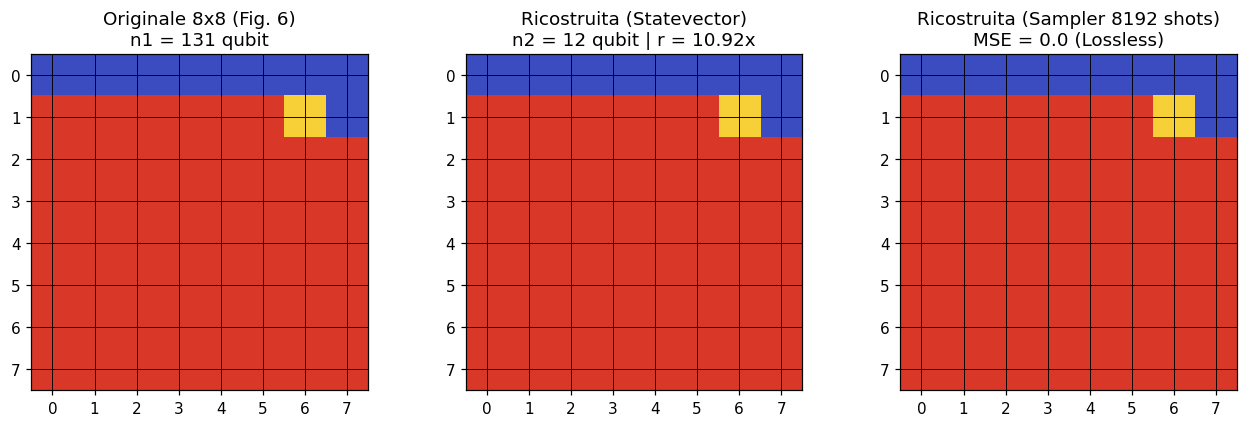

In [6]:
reconstructed_exact = decompress_image_quantum(
    benchmark_compressed, simulation_backend="statevector"
)
reconstructed_sampled = decompress_image_quantum(
    benchmark_compressed, simulation_backend="sampler", shots=8192, random_seed=42
)

mse_exact = calculate_mse(benchmark_image_8x8, reconstructed_exact)
mse_sampled = calculate_mse(benchmark_image_8x8, reconstructed_sampled)

print("=== RISULTATI TEST 1: BENCHMARK FIG. 6 (8x8) ===")
print(f"Colori distinti (m)          : {benchmark_compressed['num_distinct_colors']} (atteso: 3)")
print(f"Sequenza massima (s)         : {benchmark_compressed['max_consecutive_run']} (atteso: 53)")
print(f"Voci compresse in Q2 (n)     : {benchmark_compressed['num_compressed_entries']} (atteso: 5)")
print(f"Qubit senza compressione (n1): {benchmark_compressed['uncompressed_qubits']} (atteso: 131)")
print(f"Qubit compressi (n2)         : {benchmark_compressed['compressed_qubits']} (atteso: 12)")
print(f"Rapporto di compressione (r) : {benchmark_compressed['compression_ratio']:.4f} (articolo: 10.9)")
print(f"Ridondanza eliminata (RD)    : {benchmark_compressed['redundancy_reduction'] * 100:.2f}%")
print(f"MSE (Statevector esatto)     : {mse_exact:.6f}")
print(f"MSE (Sampler 8192 shots)     : {mse_sampled:.6f}")

assert benchmark_compressed["num_distinct_colors"] == 3
assert benchmark_compressed["max_consecutive_run"] == 53
assert benchmark_compressed["num_compressed_entries"] == 5
assert benchmark_compressed["uncompressed_qubits"] == 131
assert benchmark_compressed["compressed_qubits"] == 12
assert mse_exact == 0.0 and mse_sampled == 0.0

benchmark_colormap = ListedColormap(["#3b4cc0", "#f7d038", "#d93829"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

axes[0].imshow(benchmark_image_8x8, cmap=benchmark_colormap, vmin=0, vmax=2)
axes[0].set_title("Originale 8x8 (Fig. 6)\nn1 = 131 qubit")

axes[1].imshow(reconstructed_exact, cmap=benchmark_colormap, vmin=0, vmax=2)
axes[1].set_title(
    f"Ricostruita (Statevector)\nn2 = {benchmark_compressed['compressed_qubits']} qubit | "
    f"r = {benchmark_compressed['compression_ratio']:.2f}x"
)

axes[2].imshow(reconstructed_sampled, cmap=benchmark_colormap, vmin=0, vmax=2)
axes[2].set_title(f"Ricostruita (Sampler 8192 shots)\nMSE = {mse_sampled:.1f} (Lossless)")

for axis in axes:
    axis.set_xticks(range(8))
    axis.set_yticks(range(8))
    axis.grid(True, color="black", linewidth=0.6)

plt.tight_layout()
plt.show()

## 5. Test 2 — Confronto su Pattern Sintetici ($16 \times 16$) e Scelta della Scansione

Qui mettiamo alla prova l'algoritmo su diverse geometrie $16 \times 16$ per osservare come la struttura dell'immagine e la direzione di scansione (`row` vs `col`) influenzano il risparmio di qubit:
- **Immagine uniforme**: caso ideale con un solo colore ($m=1$).
- **Bande orizzontali e verticali**: mostrano quanto conta allineare la scansione serpentina alla direzione delle fasce.
- **Cornici concentriche**: pattern bidimensionale a 4 livelli di grigio.
- **Scacchiera $1 \times 1$**: caso limite in cui non esistono due pixel adiacenti uguali ($s=1$); qui entra in gioco la regola a **1 qubit** per i pixel intermedi isolati.

Esperimento            |   m |    s |    n | n1 (qb) | n2 (qb) | Ratio r |  RD (%) |    MSE
--------------------------------------------------------------------------------------------
Uniforme (row)         |   1 |  254 |    3 |     513 |       7 |   73.29 |   98.6% |   0.00
Bande Orizz. (row)     |   4 |   64 |    6 |     516 |      16 |   32.25 |   96.9% |   0.00
Bande Orizz. (col)     |   4 |    8 |   51 |     516 |     106 |    4.87 |   79.5% |   0.00
Bande Vert. (col)      |   4 |   64 |    6 |     516 |      16 |   32.25 |   96.9% |   0.25
Cornici (row)          |   4 |   33 |   51 |     516 |     106 |    4.87 |   79.5% |   0.00
Scacchiera 1x1 (row)   |   2 |    1 |  256 |     514 |     260 |    1.98 |   49.4% |   0.00


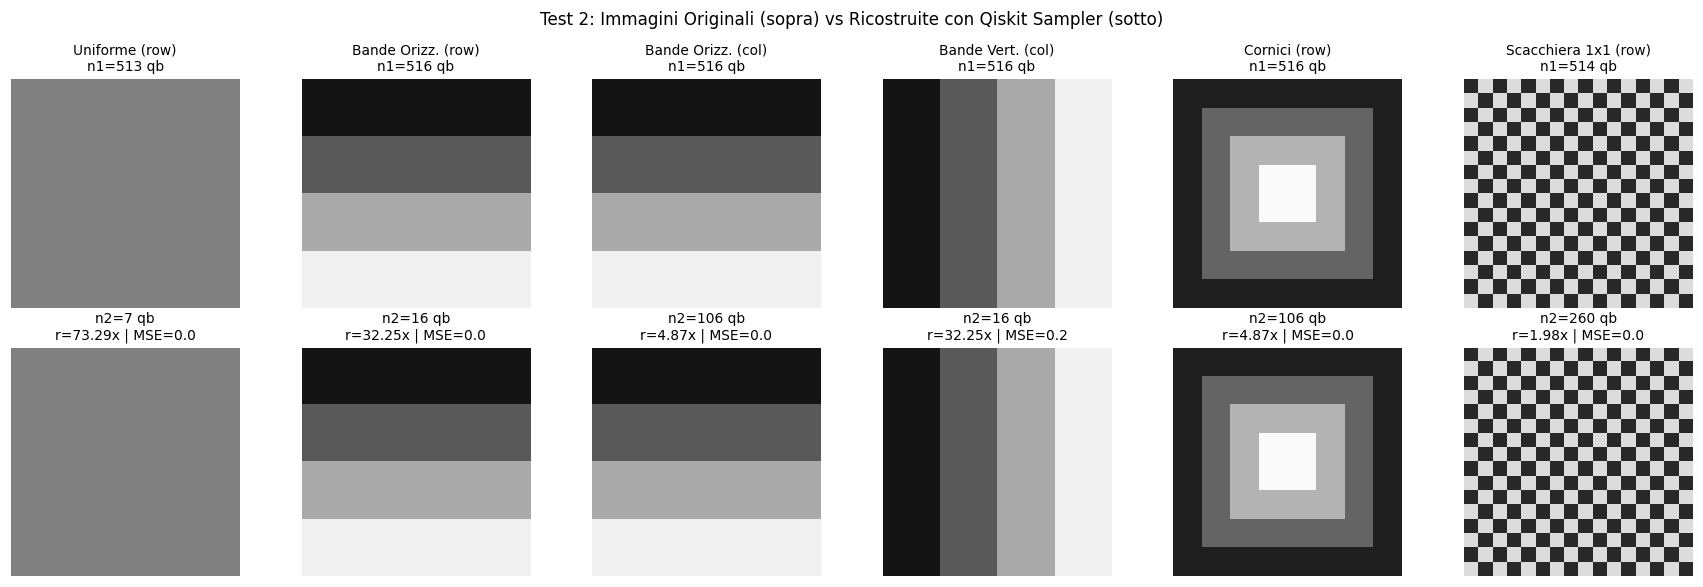

In [7]:
grid_height, grid_width = 16, 16

# 1. Immagine completamente uniforme
uniform_image = np.full((grid_height, grid_width), 128, dtype=np.int32)

# 2. Bande orizzontali (4 fasce da 4 righe ciascuna)
horizontal_stripes = np.zeros((grid_height, grid_width), dtype=np.int32)
for stripe_index, gray_value in enumerate([20, 90, 170, 240]):
    horizontal_stripes[stripe_index * 4 : (stripe_index + 1) * 4, :] = gray_value

# 3. Bande verticali (trasposta delle bande orizzontali)
vertical_stripes = horizontal_stripes.T.copy()

# 4. Cornici concentriche
concentric_frames = np.full((grid_height, grid_width), 30, dtype=np.int32)
concentric_frames[2:14, 2:14] = 100
concentric_frames[4:12, 4:12] = 180
concentric_frames[6:10, 6:10] = 250

# 5. Scacchiera alternata pixel per pixel
row_grid, col_grid = np.indices((grid_height, grid_width))
checkerboard_image = np.where((row_grid + col_grid) % 2 == 0, 40, 220).astype(np.int32)

synthetic_experiments = [
    ("Uniforme (row)", uniform_image, "row"),
    ("Bande Orizz. (row)", horizontal_stripes, "row"),
    ("Bande Orizz. (col)", horizontal_stripes, "col"),
    ("Bande Vert. (col)", vertical_stripes, "col"),
    ("Cornici (row)", concentric_frames, "row"),
    ("Scacchiera 1x1 (row)", checkerboard_image, "row"),
]

print(
    f"{'Esperimento':<22} | {'m':>3} | {'s':>4} | {'n':>4} | "
    f"{'n1 (qb)':>7} | {'n2 (qb)':>7} | {'Ratio r':>7} | {'RD (%)':>7} | {'MSE':>6}"
)
print("-" * 92)

fig, axes = plt.subplots(2, len(synthetic_experiments), figsize=(16, 5.4))

for exp_idx, (exp_label, source_img, direction) in enumerate(synthetic_experiments):
    compressed_pkg = compress_image_quantum(
        source_img, palette_size=256, scan_direction=direction, build_circuits=True
    )
    smallest_angle = np.pi / (
        2.0 * max(255, compressed_pkg["num_distinct_colors"] + compressed_pkg["max_consecutive_run"] - 1)
    )
    chosen_shots = min(32768, max(4096, estimate_required_shots(smallest_angle)))

    recovered_img = decompress_image_quantum(
        compressed_pkg,
        simulation_backend="sampler",
        shots=chosen_shots,
        random_seed=100 + exp_idx,
    )
    mse_score = calculate_mse(source_img, recovered_img)

    print(
        f"{exp_label:<22} | {compressed_pkg['num_distinct_colors']:>3} | "
        f"{compressed_pkg['max_consecutive_run']:>4} | {compressed_pkg['num_compressed_entries']:>4} | "
        f"{compressed_pkg['uncompressed_qubits']:>7} | {compressed_pkg['compressed_qubits']:>7} | "
        f"{compressed_pkg['compression_ratio']:>7.2f} | "
        f"{compressed_pkg['redundancy_reduction'] * 100:>6.1f}% | {mse_score:>6.2f}"
    )

    axes[0, exp_idx].imshow(source_img, cmap="gray", vmin=0, vmax=255)
    axes[0, exp_idx].set_title(f"{exp_label}\nn1={compressed_pkg['uncompressed_qubits']} qb", fontsize=9)
    axes[0, exp_idx].axis("off")

    axes[1, exp_idx].imshow(recovered_img, cmap="gray", vmin=0, vmax=255)
    axes[1, exp_idx].set_title(
        f"n2={compressed_pkg['compressed_qubits']} qb\n"
        f"r={compressed_pkg['compression_ratio']:.2f}x | MSE={mse_score:.1f}",
        fontsize=9,
    )
    axes[1, exp_idx].axis("off")

plt.suptitle("Test 2: Immagini Originali (sopra) vs Ricostruite con Qiskit Sampler (sotto)", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Test 3 — Quanti *Shot* Servono? Verifica Sperimentale della Soglia Teorica (Eq. 23)

Nella lettura quantistica c'è un compromesso fondamentale: se eseguiamo pochi *shot*, le fluttuazioni statistiche della misura fanno sbagliare l'arrotondamento dell'angolo; superata invece la soglia teorica $n_{\max} = \lceil n_+ \rceil$ ricavata nella Sezione 2.2 dell'articolo, gli intervalli di confidenza non si sovrappongono più e la ricostruzione diventa *lossless*.

Verifichiamo questo comportamento su una scala di grigi $8 \times 8$ ($M = 16$) facendo variare `shots` da `32` fino a `16384`.

Spaziatura angolare minima    : 0.02493 rad
Soglia teorica Eq. (23) (95%) : 9944307 shots

   Shots |        MSE |      PSNR (dB) | Pixel Esatti (%)
----------------------------------------------------------
      32 |    10.6719 |          13.24 |           12.50%
      64 |     6.2500 |          15.56 |           25.00%
     128 |     3.3125 |          18.32 |           73.44%
     256 |     3.5625 |          18.00 |           85.94%
     512 |     0.0000 | Inf (Lossless) |          100.00%
    1024 |     3.0625 |          18.66 |           98.44%
    2048 |     3.0625 |          18.66 |           98.44%
    4096 |     3.0625 |          18.66 |           98.44%
    8192 |     0.0000 | Inf (Lossless) |          100.00%
   16384 |     0.0000 | Inf (Lossless) |          100.00%


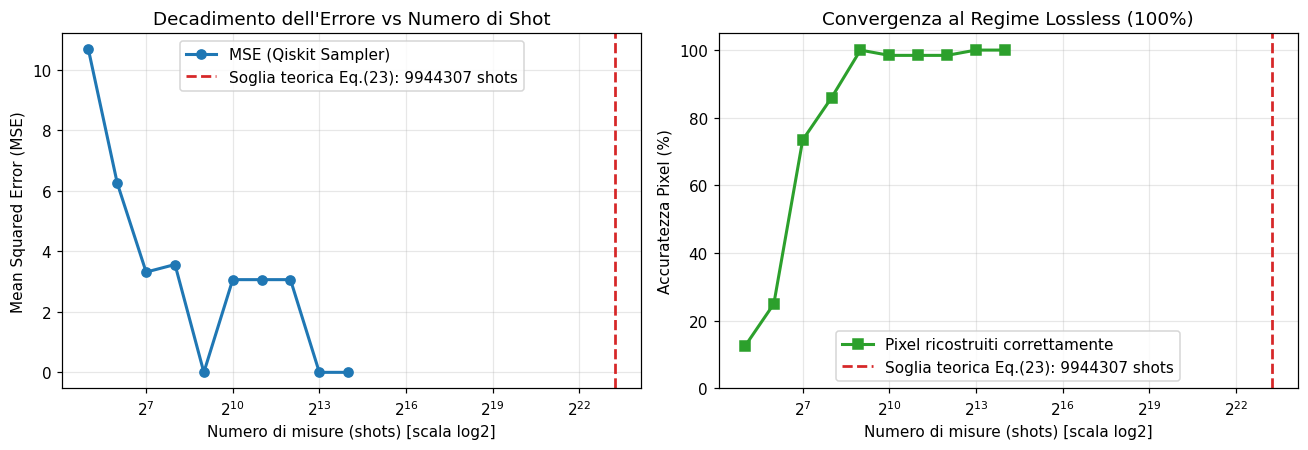

In [8]:
gradient_image_8x8 = np.repeat(np.arange(8, dtype=np.int32) * 2, 8).reshape(8, 8)
test3_palette_size = 16
gradient_compressed = compress_image_quantum(
    gradient_image_8x8,
    palette_size=test3_palette_size,
    scan_direction="row",
    build_circuits=True,
)

# Spaziatura angolare minima tra stati adiacenti nei tre registri
color_angle_step = np.pi / (2.0 * (test3_palette_size - 1))
alphabet_angle_step = np.pi / (
    2.0 * (gradient_compressed["num_distinct_colors"] + gradient_compressed["max_consecutive_run"] - 1)
)
coord_angle_step = np.pi / (2.0 * (gradient_compressed["total_pixels"] - 1))
minimum_angle_step = min(color_angle_step, alphabet_angle_step, coord_angle_step)

theoretical_shot_threshold = estimate_required_shots(
    minimum_angle_step, worst_case_prob=0.5, z_confidence=1.96
)

shot_counts_to_test = [32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]
mse_by_shots = []
exact_pixel_accuracy_by_shots = []

print(f"Spaziatura angolare minima    : {minimum_angle_step:.5f} rad")
print(f"Soglia teorica Eq. (23) (95%) : {theoretical_shot_threshold} shots\n")
print(f"{'Shots':>8} | {'MSE':>10} | {'PSNR (dB)':>14} | {'Pixel Esatti (%)':>16}")
print("-" * 58)

for shot_budget in shot_counts_to_test:
    recovered_grad = decompress_image_quantum(
        gradient_compressed,
        simulation_backend="sampler",
        shots=shot_budget,
        random_seed=77,
    )
    mse_val = calculate_mse(gradient_image_8x8, recovered_grad)
    psnr_val = calculate_psnr(
        gradient_image_8x8, recovered_grad, max_pixel_value=test3_palette_size - 1
    )
    pixel_accuracy = float(np.mean(gradient_image_8x8 == recovered_grad)) * 100.0

    mse_by_shots.append(mse_val)
    exact_pixel_accuracy_by_shots.append(pixel_accuracy)

    psnr_display = "Inf (Lossless)" if math.isinf(psnr_val) else f"{psnr_val:.2f}"
    print(f"{shot_budget:>8} | {mse_val:>10.4f} | {psnr_display:>14} | {pixel_accuracy:>15.2f}%")

fig, (ax_mse, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.2))

ax_mse.plot(
    shot_counts_to_test, mse_by_shots, marker="o", color="#1f77b4", linewidth=2, label="MSE (Qiskit Sampler)"
)
ax_mse.axvline(
    theoretical_shot_threshold,
    color="#d62728",
    linestyle="--",
    linewidth=1.8,
    label=f"Soglia teorica Eq.(23): {theoretical_shot_threshold} shots",
)
ax_mse.set_xscale("log", base=2)
ax_mse.set_xlabel("Numero di misure (shots) [scala log2]")
ax_mse.set_ylabel("Mean Squared Error (MSE)")
ax_mse.set_title("Decadimento dell'Errore vs Numero di Shot")
ax_mse.grid(True, alpha=0.3)
ax_mse.legend()

ax_acc.plot(
    shot_counts_to_test,
    exact_pixel_accuracy_by_shots,
    marker="s",
    color="#2ca02c",
    linewidth=2,
    label="Pixel ricostruiti correttamente",
)
ax_acc.axvline(
    theoretical_shot_threshold,
    color="#d62728",
    linestyle="--",
    linewidth=1.8,
    label=f"Soglia teorica Eq.(23): {theoretical_shot_threshold} shots",
)
ax_acc.set_xscale("log", base=2)
ax_acc.set_xlabel("Numero di misure (shots) [scala log2]")
ax_acc.set_ylabel("Accuratezza Pixel (%)")
ax_acc.set_ylim(0, 105)
ax_acc.set_title("Convergenza al Regime Lossless (100%)")
ax_acc.grid(True, alpha=0.3)
ax_acc.legend()

plt.tight_layout()
plt.show()

## 7. Test 4 — Applicazione ad Immagini Astrofisiche (M31) e Suddivisione in Sotto-Blocchi $8 \times 8$

Nelle moderne survey astrofisiche, la quantità di dati d'immagine raccolti dai telescopi spaziali (come Euclid, James Webb o il futuro Vera C. Rubin Observatory) è immensa. L'applicazione di tecniche di compressione quantistica lossless è estremamente promettente per ridurre drasticamente i requisiti di memoria quantistica (qubit) necessari per l'archiviazione, l'elaborazione distribuita e la trasmissione a terra dei dati astronomici, senza perdere alcun dettaglio scientifico cruciale.

In questo test, carichiamo un'immagine reale della **Galassia di Andromeda (M31)**, la convertiamo in scala di grigi a 256 livelli e confrontiamo due strategie di compressione:
1. **Compressione globale**: l'algoritmo elabora l'intera immagine astronomica in un'unica passata.
2. **Compressione a sotto-blocchi $8 \times 8$**: l'immagine viene divisa in tasselli $8 \times 8$ indipendenti. Ogni tassello del profondo cielo presenta regioni locali altamente uniformi (es. il fondo cielo o i bracci galattici sfumati), riducendo il numero di colori locali distinti ($m$) e le lunghezze delle sequenze ($s$). Questo aumenta notevolmente la separazione angolare $\Delta\gamma$ e rende il recupero tramite misure quantistiche eccezionalmente robusto.

=== RIEPILOGO TEST 4: IMMAGINI ASTROFISICHE DI M31 (M = 256) ===
[64x64 Globale (col)]      m=249, s=3, n=3909 | n1=8441, n2=4341 | r=1.944x
[64x64 Sotto-blocchi 8x8]  max_m=56, max_s=3 | n1=10426, n2=6452 | r=1.616x | MSE=0.0000
[256x256 Globale (col)]    m=256, s=10, n=60629 | n1=131328, n2=65154 | r=2.016x


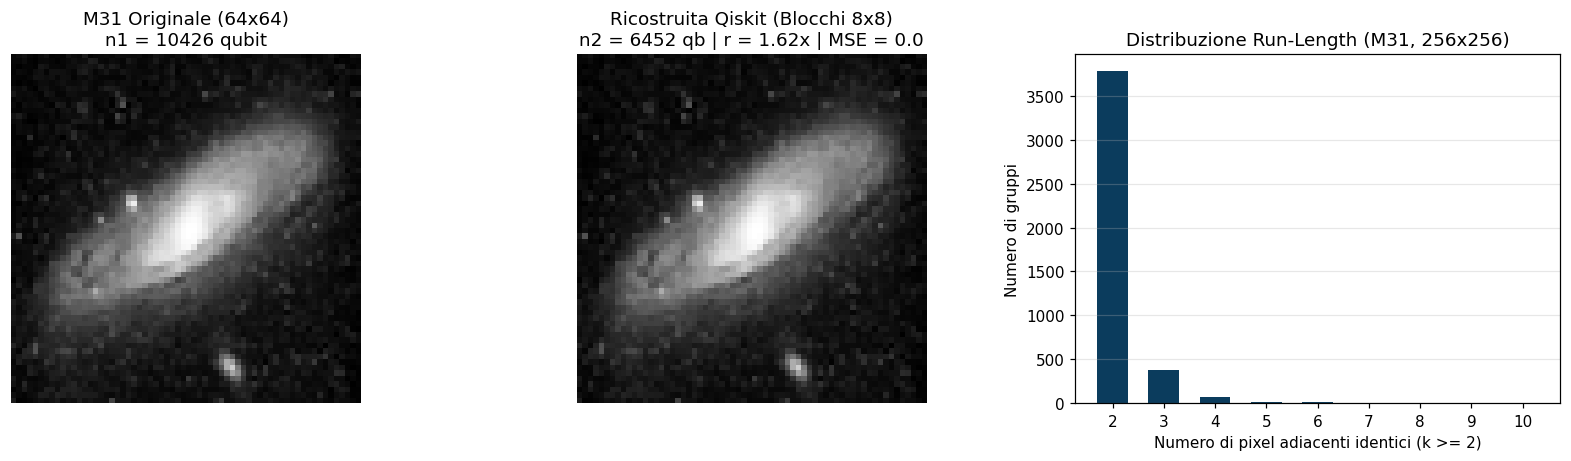

In [9]:
import requests
from PIL import Image
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt

# Scarichiamo l'immagine astronomica di M31 (Andromeda)
img_url = "https://www.astronomia.com/wp-content/uploads/2007/06/m31-big.jpg"
try:
    response = requests.get(img_url, timeout=15)
    m31_pil = Image.open(BytesIO(response.content)).convert("L")
except Exception as e:
    print(f"Errore nel download dell'immagine di M31: {e}. Utilizzo fallback sintetico.")
    # Fallback in caso di problemi di rete
    m31_pil = Image.fromarray((data.coins()).astype(np.uint8))

# Ridimensioniamo l'immagine astronomica per i nostri test quantistici
photo_64x64 = np.array(m31_pil.resize((64, 64), Image.Resampling.LANCZOS), dtype=np.int32)
photo_256x256 = np.array(m31_pil.resize((256, 256), Image.Resampling.LANCZOS), dtype=np.int32)

# 1. Compressione globale su 64x64 e 256x256 con scansione per colonne
global_pkg_64 = compress_image_quantum(
    photo_64x64, palette_size=256, scan_direction="col", build_circuits=False
)
global_pkg_256 = compress_image_quantum(
    photo_256x256, palette_size=256, scan_direction="col", build_circuits=False
)

# 2. Compressione a sotto-blocchi 8x8 sull'immagine 64x64 (64 tasselli totali)
subblock_size = 8
total_uncompressed_qubits_blocks = 0
total_compressed_qubits_blocks = 0
max_block_run = 0
max_block_colors = 0
reconstructed_photo_64 = np.zeros_like(photo_64x64)

for top_row in range(0, 64, subblock_size):
    for left_col in range(0, 64, subblock_size):
        image_block = photo_64x64[top_row : top_row + subblock_size, left_col : left_col + subblock_size]
        block_pkg = compress_image_quantum(
            image_block, palette_size=256, scan_direction="col", build_circuits=False
        )
        total_uncompressed_qubits_blocks += block_pkg["uncompressed_qubits"]
        total_compressed_qubits_blocks += block_pkg["compressed_qubits"]
        max_block_run = max(max_block_run, block_pkg["max_consecutive_run"])
        max_block_colors = max(max_block_colors, block_pkg["num_distinct_colors"])

        # Ricostruzione quantistica tramite Qiskit Statevector
        reconstructed_photo_64[
            top_row : top_row + subblock_size, left_col : left_col + subblock_size
        ] = decompress_image_quantum(block_pkg, simulation_backend="statevector")

block_compression_ratio = total_uncompressed_qubits_blocks / total_compressed_qubits_blocks
block_reconstruction_mse = calculate_mse(photo_64x64, reconstructed_photo_64)

print("=== RIEPILOGO TEST 4: IMMAGINI ASTROFISICHE DI M31 (M = 256) ===")
print(
    f"[64x64 Globale (col)]      m={global_pkg_64['num_distinct_colors']}, "
    f"s={global_pkg_64['max_consecutive_run']}, n={global_pkg_64['num_compressed_entries']} | "
    f"n1={global_pkg_64['uncompressed_qubits']}, n2={global_pkg_64['compressed_qubits']} | "
    f"r={global_pkg_64['compression_ratio']:.3f}x"
)
print(
    f"[64x64 Sotto-blocchi 8x8]  max_m={max_block_colors}, max_s={max_block_run} | "
    f"n1={total_uncompressed_qubits_blocks}, n2={total_compressed_qubits_blocks} | "
    f"r={block_compression_ratio:.3f}x | MSE={block_reconstruction_mse:.4f}"
)
print(
    f"[256x256 Globale (col)]    m={global_pkg_256['num_distinct_colors']}, "
    f"s={global_pkg_256['max_consecutive_run']}, n={global_pkg_256['num_compressed_entries']} | "
    f"n1={global_pkg_256['uncompressed_qubits']}, n2={global_pkg_256['compressed_qubits']} | "
    f"r={global_pkg_256['compression_ratio']:.3f}x"
)

# Distribuzione delle lunghezze dei gruppi di pixel adiacenti identici (k >= 2)
adjacent_run_lengths = [
    entry["run_length"]
    for entry in global_pkg_256["compressed_entries"]
    if entry["entry_type"] == "pixel_run" and entry["run_length"] >= 2
]
run_lengths_values, group_counts = np.unique(adjacent_run_lengths, return_counts=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].imshow(photo_64x64, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"M31 Originale (64x64)\nn1 = {total_uncompressed_qubits_blocks} qubit")
axes[0].axis("off")

axes[1].imshow(reconstructed_photo_64, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(
    f"Ricostruita Qiskit (Blocchi 8x8)\n"
    f"n2 = {total_compressed_qubits_blocks} qb | r = {block_compression_ratio:.2f}x | MSE = {block_reconstruction_mse:.1f}"
)
axes[1].axis("off")

display_mask = run_lengths_values <= 12
axes[2].bar(run_lengths_values[display_mask], group_counts[display_mask], color="#0b3c5d", width=0.6)
axes[2].set_xlabel("Numero di pixel adiacenti identici (k >= 2)")
axes[2].set_ylabel("Numero di gruppi")
axes[2].set_title("Distribuzione Run-Length (M31, 256x256)")
axes[2].set_xticks(run_lengths_values[display_mask])
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()